<a href="https://colab.research.google.com/github/jamescondoliza-maker/Stroke-Prediction-Model/blob/main/final_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



P 4



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data (1).csv


In [ ]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
print(df.head())

      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  


check the dataset information

In [ ]:
print("Dataset shape:", df.shape)
print("\nDataset information:")
print(df.columns)

Dataset shape: (5110, 12)

Dataset information:
Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


cheking missing values

In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

id                   0.000000
gender               0.000000
age                  0.000000
hypertension         0.000000
heart_disease        0.000000
ever_married         0.000000
work_type            0.000000
Residence_type       0.000000
avg_glucose_level    0.000000
bmi                  3.933464
smoking_status       0.000000
stroke               0.000000
dtype: float64


check duplicate records

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicate rows removed. New shape:", df.shape)

Number of duplicate rows: 0
Duplicate rows removed. New shape: (5110, 12)


check data types

In [ ]:
print(df.dtypes)

id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object


The distribution of the target variable

In [ ]:
print(df["stroke"].value_counts())
print("\nStroke percentages:")
print(df["stroke"].value_counts(normalize=True) * 100)

stroke
0    4861
1     249
Name: count, dtype: int64

Stroke percentages:
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


cleaning the dataset

In [ ]:
df = df.drop_duplicates()
print("Dataset shape after removing duplicates:")
print(df.shape)

Dataset shape after removing duplicates:
(5110, 12)


removing unnecessary columns

In [ ]:
if "id" in df.columns:
 df = df.drop(columns=["id"])
print(df.head())

   gender   age  hypertension  heart_disease ever_married      work_type  \
0    Male  67.0             0              1          Yes        Private   
1  Female  61.0             0              0          Yes  Self-employed   
2    Male  80.0             0              1          Yes        Private   
3  Female  49.0             0              0          Yes        Private   
4  Female  79.0             1              0          Yes  Self-employed   

  Residence_type  avg_glucose_level   bmi   smoking_status  stroke  
0          Urban             228.69  36.6  formerly smoked       1  
1          Rural             202.21   NaN     never smoked       1  
2          Rural             105.92  32.5     never smoked       1  
3          Urban             171.23  34.4           smokes       1  
4          Rural             174.12  24.0     never smoked       1  


Displaying missing values using a heatmap

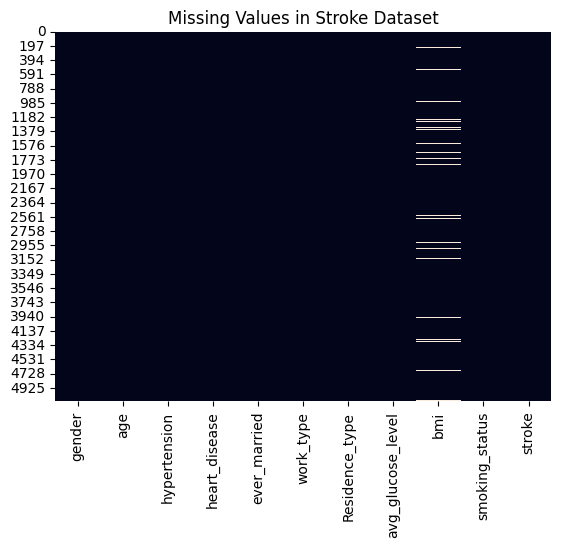

In [ ]:
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values in Stroke Dataset")
plt.show()

Handling missing bmi

In [ ]:
bmi_mean = df["bmi"].median()
df["bmi"] = df["bmi"].fillna(bmi_mean)
print(df.isnull().sum())

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [ ]:
categorical_columns = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"]
for col in categorical_columns:
  df[col] = df[col].astype("string").str.strip()
  print(df[col].unique())

<StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: string
<StringArray>
['Yes', 'No']
Length: 2, dtype: string
<StringArray>
['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Length: 5, dtype: string
<StringArray>
['Urban', 'Rural']
Length: 2, dtype: string
<StringArray>
['formerly smoked', 'never smoked', 'smokes', 'Unknown']
Length: 4, dtype: string


Handling unknown smoking status

In [ ]:
print(df["smoking_status"].value_counts())

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: Int64


check the cleaned dataset

In [ ]:
print("Missing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [ ]:
print("\nDuplicate records:")
print(df.duplicated().sum())


Duplicate records:
0


In [ ]:
print("\nCleaned dataset:")
print(df.head())


Cleaned dataset:
   gender   age  hypertension  heart_disease ever_married      work_type  \
0    Male  67.0             0              1          Yes        Private   
1  Female  61.0             0              0          Yes  Self-employed   
2    Male  80.0             0              1          Yes        Private   
3  Female  49.0             0              0          Yes        Private   
4  Female  79.0             1              0          Yes  Self-employed   

  Residence_type  avg_glucose_level   bmi   smoking_status  stroke  
0          Urban             228.69  36.6  formerly smoked       1  
1          Rural             202.21  28.1     never smoked       1  
2          Rural             105.92  32.5     never smoked       1  
3          Urban             171.23  34.4           smokes       1  
4          Rural             174.12  24.0     never smoked       1  


separate features and targets

In [ ]:
X = df.drop("stroke", axis=1)
y = df["stroke"]
print("Features:")
print(X.head())
print("\nTarget:")
print(y.head())

Features:
   gender   age  hypertension  heart_disease ever_married      work_type  \
0    Male  67.0             0              1          Yes        Private   
1  Female  61.0             0              0          Yes  Self-employed   
2    Male  80.0             0              1          Yes        Private   
3  Female  49.0             0              0          Yes        Private   
4  Female  79.0             1              0          Yes  Self-employed   

  Residence_type  avg_glucose_level   bmi   smoking_status  
0          Urban             228.69  36.6  formerly smoked  
1          Rural             202.21  28.1     never smoked  
2          Rural             105.92  32.5     never smoked  
3          Urban             171.23  34.4           smokes  
4          Rural             174.12  24.0     never smoked  

Target:
0    1
1    1
2    1
3    1
4    1
Name: stroke, dtype: int64


split training and testing data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (4088, 10)
Testing features: (1022, 10)
Training target: (4088,)
Testing target: (1022,)


identifying numerical and categorical column

In [ ]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns
print("Numerical columns:")
print(list(numeric_features))
print("\nCategorical columns:")
print(list(categorical_features))

Numerical columns:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']

Categorical columns:
[]


Encode categorical data and handle missing values

In [ ]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

Combining both preprocessing method

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

performing feature scaling

In [ ]:
X_train_prepared = preprocessor.fit_transform(X_train)
print("Training data prepared successfully")
print("Training data shape:", X_train_prepared.shape)

Training data prepared successfully
Training data shape: (4088, 5)


transform the testing data

In [ ]:
X_test_prepared = preprocessor.transform(X_test)
print("Testing data prepared successfully")
print("Testing data shape:", X_test_prepared.shape)

Testing data prepared successfully
Testing data shape: (1022, 5)


Final data checks

In [ ]:
print("Final training dataset shape:")
print(X_train_prepared.shape)

print("\nFinal testing dataset shape:")
print(X_test_prepared.shape)

print("\nMissing values in training target:")
print(y_train.isnull().sum())

print("\nMissing values in testing target:")
print(y_test.isnull().sum())

print("\nTraining stroke distribution:")
print(y_train.value_counts())

print("\nTesting stroke distribution:")
print(y_test.value_counts())

Final training dataset shape:
(4088, 5)

Final testing dataset shape:
(1022, 5)

Missing values in training target:
0

Missing values in testing target:
0

Training stroke distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing stroke distribution:
stroke
0    972
1     50
Name: count, dtype: int64


M2 .Review the original dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
print("Original dataset:")
print(df.head())

Original dataset:
      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  


check the dataset size

In [ ]:
print("Number of rows and columns:")
print(df.shape)

Number of rows and columns:
(5110, 12)


identifying the missing values

In [ ]:
print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


identify duplicate

In [ ]:
print("Duplicate records before cleaning:")
print(df.duplicated().sum())

Duplicate records before cleaning:
0


the percentage of missing values


In [ ]:
missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

print(missing_report)

                   Missing Values  Missing Percentage
id                              0            0.000000
gender                          0            0.000000
age                             0            0.000000
hypertension                    0            0.000000
heart_disease                   0            0.000000
ever_married                    0            0.000000
work_type                       0            0.000000
Residence_type                  0            0.000000
avg_glucose_level               0            0.000000
bmi                           201            3.933464
smoking_status                  0            0.000000
stroke                          0            0.000000


visualise missing values

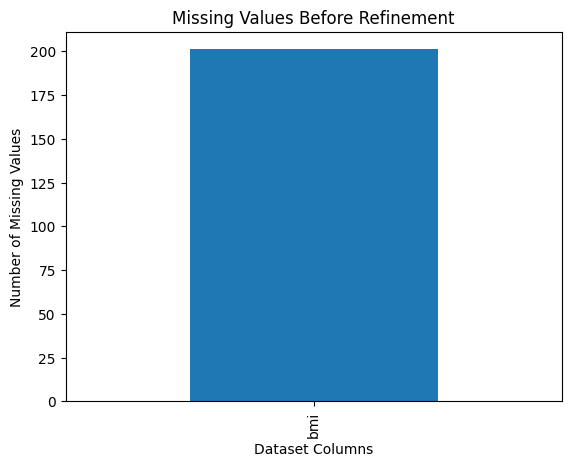

In [ ]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

missing_values.plot(kind="bar")

plt.title("Missing Values Before Refinement")
plt.xlabel("Dataset Columns")
plt.ylabel("Number of Missing Values")

plt.show()

removing duplicate and unnecessary column

In [ ]:
df_refined = df.copy()

df_refined = df_refined.drop_duplicates()

if "id" in df_refined.columns:
    df_refined = df_refined.drop(columns=["id"])

print("Dataset after removing duplicates and ID:")
print(df_refined.shape)

Dataset after removing duplicates and ID:
(5110, 11)


separate numerical and categorical features

In [ ]:
X = df_refined.drop("stroke", axis=1)

y = df_refined["stroke"]

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns

spliting the data

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Applying median and categorical imputation

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

X_train_prepared = preprocessor.fit_transform(X_train)

X_test_prepared = preprocessor.transform(X_test)

print("Training data refined successfully")
print("Testing data refined successfully")

Training data refined successfully
Testing data refined successfully


check the original class distribution

In [ ]:
print("Stroke distribution before balancing:")
print(y_train.value_counts())
print("\nClass percentages:")
print(y_train.value_counts(normalize=True) * 100)

Stroke distribution before balancing:
stroke
0    3889
1     199
Name: count, dtype: int64

Class percentages:
stroke
0    95.132094
1     4.867906
Name: proportion, dtype: float64


visualise the class imbalance

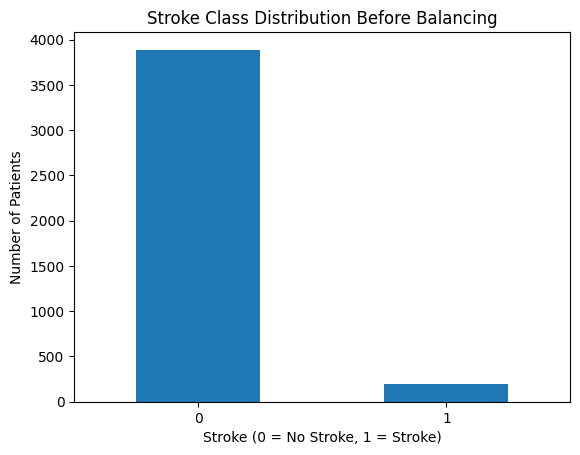

In [ ]:
y_train.value_counts().plot(
    kind="bar",
    rot=0
)
plt.title("Stroke Class Distribution Before Balancing")
plt.xlabel("Stroke (0 = No Stroke, 1 = Stroke)")
plt.ylabel("Number of Patients")
plt.show()

In [ ]:
!pip install imbalanced-learn

In [ ]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train_prepared,
    y_train
)

print("Class distribution after balancing:")
print(y_train_balanced.value_counts())

Class distribution after balancing:
stroke
0    3889
1    3889
Name: count, dtype: int64


compare class distribution before and after balancing

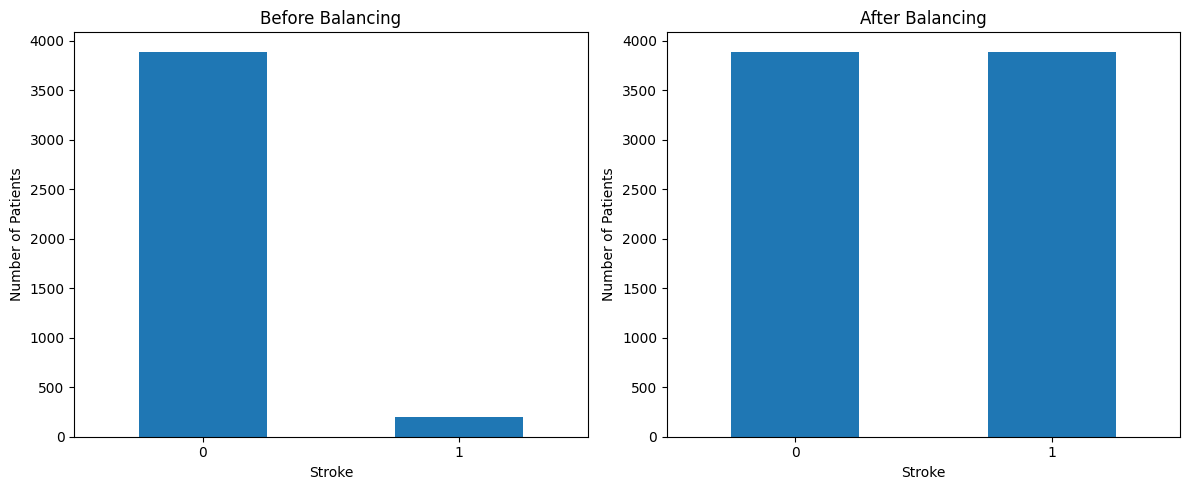

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

y_train.value_counts().sort_index().plot(
    kind="bar", ax=axes[0], rot=0
)

axes[0].set_title("Before Balancing")
axes[0].set_xlabel("Stroke")
axes[0].set_ylabel("Number of Patients")

y_train_balanced.value_counts().sort_index().plot(
    kind="bar", ax=axes[1], rot=0
)

axes[1].set_title("After Balancing")
axes[1].set_xlabel("Stroke")
axes[1].set_ylabel("Number of Patients")

plt.tight_layout()
plt.show()

before and after data quality comparision

In [ ]:
comparison = pd.DataFrame({
    "Before Refinement": [
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df.shape[0],
        df.shape[1]
    ],
    "After Refinement": [
        X_train.isnull().sum().sum(),
        X_train.duplicated().sum(),
        X_train.shape[0],
        X_train.shape[1]
    ]
}, index=[
    "Missing values in raw/training features",
    "Duplicate rows",
    "Number of records",
    "Number of features"
])

print(comparison)

                                         Before Refinement  After Refinement
Missing values in raw/training features                201               170
Duplicate rows                                           0                 0
Number of records                                     5110              4088
Number of features                                      12                10


checking missing values

In [ ]:
if hasattr(X_train_prepared, "toarray"):
    prepared_data = X_train_prepared.toarray()
else:
    prepared_data = X_train_prepared

print("Missing values after preprocessing:",
      np.isnan(prepared_data).sum())

Missing values after preprocessing: 0


compare the class distribution

In [ ]:
print("BEFORE REFINEMENT:")
print(y_train.value_counts())


BEFORE REFINEMENT:
stroke
0    3889
1     199
Name: count, dtype: int64


In [ ]:
print("\nAFTER REFINEMENT:")
print(y_train_balanced.value_counts())


AFTER REFINEMENT:
stroke
0    3889
1    3889
Name: count, dtype: int64


 M3 .developing an AI solution using Logistic Regression



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("All libraries imported successfully")

All libraries imported successfully


checking the prepared dataset

In [ ]:
print("Training data:", X_train_balanced.shape)
print("Training labels:", y_train_balanced.shape)

print("Testing data:", X_test_prepared.shape)
print("Testing labels:", y_test.shape)

Training data: (7778, 21)
Training labels: (7778,)
Testing data: (1022, 21)
Testing labels: (1022,)


creating the Logistic regression model

In [ ]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Logistic Regression model created successfully")

Logistic Regression model created successfully


Training the model

In [ ]:
model.fit(X_train_balanced, y_train_balanced)

print("Model training completed successfully!")

Model training completed successfully!


Make predictions

In [ ]:
y_pred = model.predict(X_test_prepared)
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})
print(results.head(10))

      Actual  Predicted
3725       0          0
4481       0          0
1545       0          0
1820       0          0
1262       0          1
3618       0          0
254        0          0
628        0          0
3426       0          0
2687       0          0


The model accuracy

The evaluation metrics

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Model Accuracy: 74.46183953033268 %
Accuracy: 0.7446183953033269
Precision: 0.13745704467353953
Recall: 0.8
F1 Score: 0.23460410557184752


display the classification report

In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Stroke", "Stroke"],
    zero_division=0
))

              precision    recall  f1-score   support

   No Stroke       0.99      0.74      0.85       972
      Stroke       0.14      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.82      1022



The confusion matrix

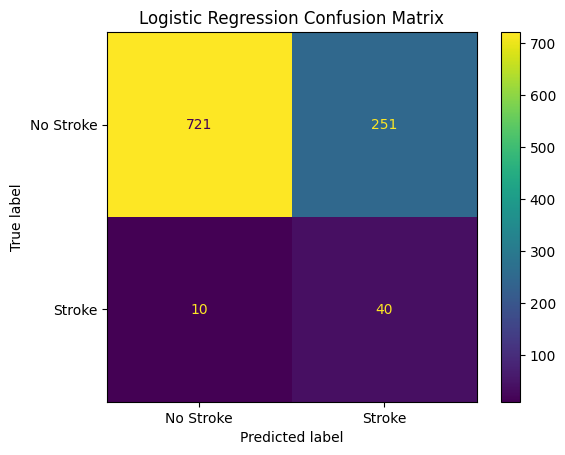

In [ ]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Stroke", "Stroke"]
)

disp.plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

Visualising the model performance

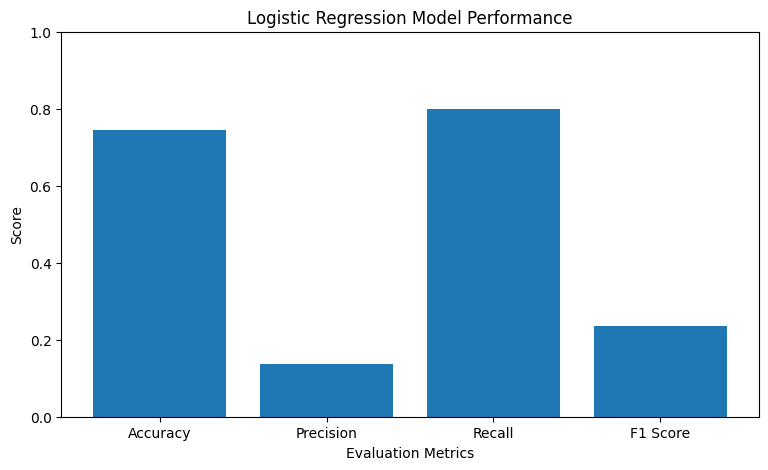

In [ ]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

plt.figure(figsize=(9, 5))

plt.bar(metrics.keys(), metrics.values())

plt.title("Logistic Regression Model Performance")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")

plt.ylim(0, 1)

plt.show()

The ROC curve

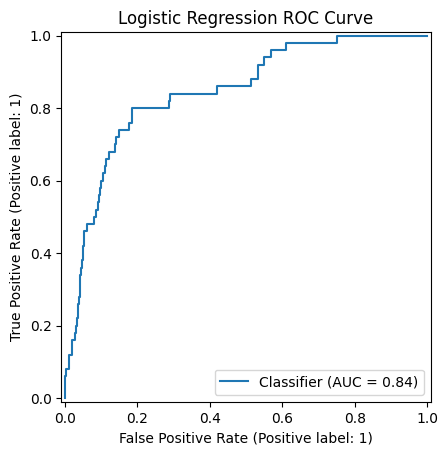

ROC AUC Score: 0.8444650205761317


In [ ]:
y_prob = model.predict_proba(X_test_prepared)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("Logistic Regression ROC Curve")
plt.show()

print("ROC AUC Score:", roc_auc)

Testing an individual patient

In [ ]:

sample_patient = X_test.iloc[[0]]
sample_prepared = preprocessor.transform(sample_patient
prediction = model.predict(sample_prepared)
if prediction[0] == 1:
    print("Prediction: Stroke")
else:
    print("Prediction: No Stroke")

Prediction: No Stroke


Train the initial model

In [ ]:
from sklearn.linear_model import LogisticRegression

initial_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

initial_model.fit(X_train_prepared, y_train)

print("Initial model trained successfully!")

Initial model trained successfully!


Make initial predictions

In [ ]:
y_pred_initial = initial_model.predict(X_test_prepared)

print("Initial predictions:")
print(y_pred_initial[:20])

Initial predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


The initial performance metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy_initial = accuracy_score(
    y_test, y_pred_initial
)

precision_initial = precision_score(
    y_test, y_pred_initial, zero_division=0
)

recall_initial = recall_score(
    y_test, y_pred_initial, zero_division=0
)

f1_initial = f1_score(
    y_test, y_pred_initial, zero_division=0
)

roc_initial = roc_auc_score(
    y_test,
    initial_model.predict_proba(X_test_prepared)[:, 1]
)

print("INITIAL MODEL RESULTS")
print("Accuracy:", accuracy_initial)
print("Precision:", precision_initial)
print("Recall:", recall_initial)
print("F1 Score:", f1_initial)
print("ROC AUC Score:", roc_initial)


INITIAL MODEL RESULTS
Accuracy: 0.952054794520548
Precision: 1.0
Recall: 0.02
F1 Score: 0.0392156862745098
ROC AUC Score: 0.8416666666666667


Display the classification report

In [ ]:
print(classification_report(
    y_test,
    y_pred_initial,
    target_names=["No Stroke", "Stroke"],
    zero_division=0
))

              precision    recall  f1-score   support

   No Stroke       0.95      1.00      0.98       972
      Stroke       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



Generating the initial Confusion matrix

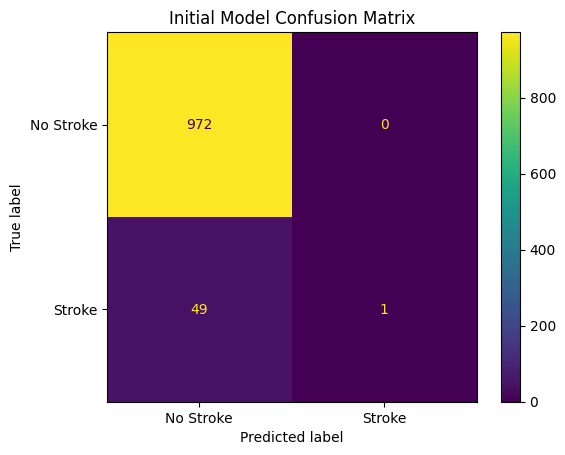

In [ ]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_initial,
    display_labels=["No Stroke", "Stroke"]
)

plt.title("Initial Model Confusion Matrix")
plt.show()

Handle class imbalance

In [ ]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train_prepared,
    y_train
)

print("Class distribution after refinement:")
print(y_train_balanced.value_counts())

Class distribution after refinement:
stroke
0    3889
1    3889
Name: count, dtype: int64


Handling class imbalance

p5


In [ ]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train_prepared,
    y_train
)

print("Class distribution after refinement:")
print(y_train_balanced.value_counts())

Class distribution after refinement:
stroke
0    3889
1    3889
Name: count, dtype: int64


Adjusting Logistic Regression hyperparameters

---



In [ ]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import LogisticRegression

refined_pipeline = Pipeline(steps=[
    ("sampler", RandomOverSampler(random_state=42)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["liblinear", "lbfgs"]
}

grid_search = GridSearchCV(
    estimator=refined_pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train_prepared, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation recall:")
print(grid_search.best_score_)

Best parameters:
{'classifier__C': 0.1, 'classifier__solver': 'liblinear'}

Best cross-validation recall:
0.8039743589743591


Select the best model

In [ ]:
refined_model = grid_search.best_estimator_

print("Refined Logistic Regression model selected!")

Refined Logistic Regression model selected!


Make prediction

In [ ]:
y_pred_refined = refined_model.predict(X_test_prepared)

print("Refined model predictions:")
print(y_pred_refined[:20])

Refined model predictions:
[0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0]


Calculate refined model performance

In [ ]:
accuracy_refined = accuracy_score(
    y_test, y_pred_refined
)

precision_refined = precision_score(
    y_test, y_pred_refined, zero_division=0
)

recall_refined = recall_score(
    y_test, y_pred_refined, zero_division=0
)

f1_refined = f1_score(
    y_test, y_pred_refined, zero_division=0
)

roc_refined = roc_auc_score(
    y_test,
    refined_model.predict_proba(X_test_prepared)[:, 1]
)

print("REFINED MODEL RESULTS")
print("---------------------")
print("Accuracy:", accuracy_refined)
print("Precision:", precision_refined)
print("Recall:", recall_refined)
print("F1 Score:", f1_refined)
print("ROC AUC:", roc_refined)

REFINED MODEL RESULTS
---------------------
Accuracy: 0.7446183953033269
Precision: 0.13745704467353953
Recall: 0.8
F1 Score: 0.23460410557184752
ROC AUC: 0.8431069958847736


Compare the initial and refined model

In [ ]:
comparison = pd.DataFrame({
    "Initial Model": [
        accuracy_initial,
        precision_initial,
        recall_initial,
        f1_initial,
        roc_initial
    ],

    "Refined Model": [
        accuracy_refined,
        precision_refined,
        recall_refined,
        f1_refined,
        roc_refined
    ]

}, index=[
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
])

print(comparison.round(4))

           Initial Model  Refined Model
Accuracy          0.9521         0.7446
Precision         1.0000         0.1375
Recall            0.0200         0.8000
F1 Score          0.0392         0.2346
ROC AUC           0.8417         0.8431


The performance changes

In [ ]:
improvement = (
    comparison["Refined Model"] -
    comparison["Initial Model"]
)

print("Performance changes:")
print(improvement.round(4))

Performance changes:
Accuracy    -0.2074
Precision   -0.8625
Recall       0.7800
F1 Score     0.1954
ROC AUC      0.0014
dtype: float64


Visualise the comparision

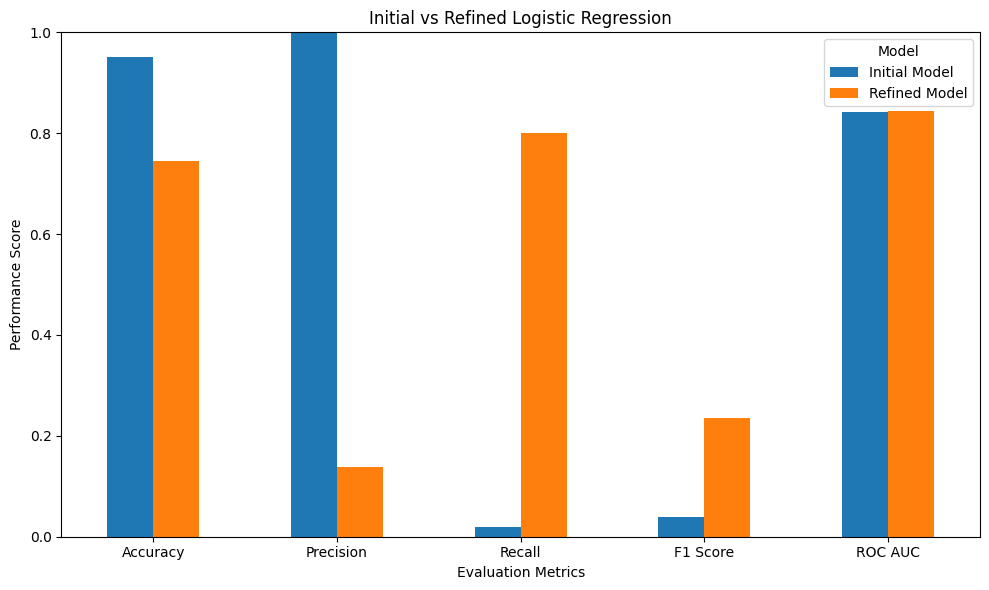

In [ ]:
comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Initial vs Refined Logistic Regression")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Performance Score")

plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")

plt.tight_layout()
plt.show()

Initial model confusion matrix

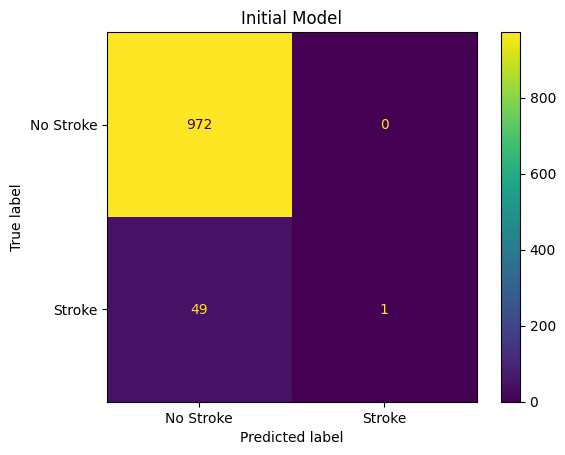

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_initial,
    display_labels=["No Stroke", "Stroke"]
)

plt.title("Initial Model")
plt.show()

Refined model confusion matrix

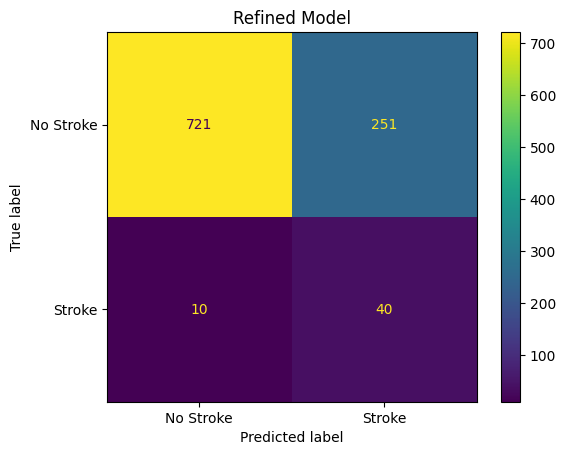

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_refined,
    display_labels=["No Stroke", "Stroke"]
)

plt.title("Refined Model")
plt.show()